# Instacart Market Basket Analysis — Minor Project 02 (CA 03)
**CSB314 | Exploratory Data Analysis | UNIT IV + UNIT V**

**Kaggle source:** https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis

**Question:** What patterns can be identified in grocery-order timing, basket size, departments and reorder behaviour?

## How to use
1. Keep this notebook beside your `data` folder.
2. Put `orders.csv`, `order_products__prior.csv`, `order_products__train.csv`, `products.csv`, `aisles.csv`, and `departments.csv` inside `data`.
3. Run every cell from top to bottom. If the kernel restarts, run all cells again.
4. Save the notebook after execution so actual tables and graphs are stored.
5. Large order-product files are scanned in chunks. Exact per-order counts are accumulated; detailed product-line joins use a reproducible sample and are labelled as such.

**Important:** No findings are invented in advance. Actual values are generated from your CSV files. Check the current Kaggle licence/usage terms yourself before submission.

## Problem statement and objectives
Explore order timing, basket size, department patterns and reorder behaviour. Create meaningful features; group and aggregate; reshape and integrate related tables; calculate descriptive statistics; examine distributions, sampling, correlation and outliers; and assess data quality.

## Dataset tables and grain

| CSV | One row represents | Key columns |
|---|---|---|
| orders.csv | one order | order_id, user_id, order_number, order_dow, order_hour_of_day |
| order_products__prior.csv | one product line in a prior order | order_id, product_id, add_to_cart_order, reordered |
| order_products__train.csv | one product line in a train order | order_id, product_id, add_to_cart_order, reordered |
| products.csv | one product | product_id, aisle_id, department_id |
| aisles.csv | one aisle | aisle_id |
| departments.csv | one department | department_id |

Relationships: one order to many product lines; products to many observed product lines; products reference aisle and department lookup tables. Instacart has day/hour and days-since-prior-order fields, not a full timestamp. Keep raw data unchanged and use working copies.

# 1. Import libraries
**Objective:** load tools for tables, numerical analysis and plots. Pandas manages DataFrames; NumPy supports calculations and sampling; Matplotlib/Seaborn create charts; pathlib handles relative paths.

In [1]:
# If Seaborn is missing, uncomment the next line, run it, restart kernel, then Run All.
# %pip install pandas numpy matplotlib seaborn

import gc, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
print("Pandas", pd.__version__, "| NumPy", np.__version__, "| Seaborn", sns.__version__)

Pandas 3.0.2 | NumPy 2.4.4 | Seaborn 0.13.2


# 2. Verify the data folder
**Objective:** fail early with a clear message if a required CSV is missing. The notebook uses a relative `data` path.

In [2]:
DATA_DIR = Path("data")
FILES = ["orders.csv", "order_products__prior.csv", "order_products__train.csv",
         "products.csv", "aisles.csv", "departments.csv"]
missing = [f for f in FILES if not (DATA_DIR / f).is_file()]
if missing:
    raise FileNotFoundError("Missing in ./data: " + ", ".join(missing))
display(pd.DataFrame([{"file": f, "size_MB": round((DATA_DIR/f).stat().st_size/1024**2, 2)}
                      for f in FILES]).sort_values("size_MB", ascending=False))
print("All six files found.")

,file,size_MB
1,order_products__prior.csv,550.80
0,orders.csv,103.92
2,order_products__train.csv,23.54
3,products.csv,2.07
4,aisles.csv,0.00
5,departments.csv,0.00


All six files found.


# 3. Load smaller tables
**Method:** compact integer/category types reduce memory. `raw_` tables are preserved unchanged. Review the shapes and memory report.

In [3]:
def read_table(name, dtype=None):
    t = time.time()
    print("Loading", name, flush=True)
    df = pd.read_csv(DATA_DIR/name, dtype=dtype)
    print(df.shape, "elapsed sec:", round(time.time()-t, 1), flush=True)
    return df

raw_orders = read_table("orders.csv", {
    "order_id":"int32", "user_id":"int32", "eval_set":"category",
    "order_number":"int16", "order_dow":"int8", "order_hour_of_day":"int8",
    "days_since_prior_order":"float32"})
raw_products = read_table("products.csv", {
    "product_id":"int32", "aisle_id":"int16", "department_id":"int16"})
raw_aisles = read_table("aisles.csv", {"aisle_id":"int16"})
raw_departments = read_table("departments.csv", {"department_id":"int16"})

display(pd.DataFrame([
    {"table":n, "rows":len(d), "columns":len(d.columns),
     "memory_MB":round(d.memory_usage(deep=True).sum()/1024**2,2)}
    for n,d in {"orders":raw_orders,"products":raw_products,
                "aisles":raw_aisles,"departments":raw_departments}.items()
]))

Loading orders.csv
(3421083, 7) elapsed sec: 1.7
Loading products.csv
(49688, 4) elapsed sec: 0.1
Loading aisles.csv
(134, 2) elapsed sec: 0.0
Loading departments.csv
(21, 2) elapsed sec: 0.0


,table,rows,columns,memory_MB
0,orders,3421083,7,55.46
1,products,49688,4,2.22
2,aisles,134,2,0.00
3,departments,21,2,0.00


# 4. Chunk-process the large order-product files
**Objective:** avoid loading the complete product-line CSVs into RAM. For each chunk, accumulate per-order basket counts and retain a fixed-seed row sample for detailed product-line analysis. The summary counts are based on every scanned row; the product-line fact table later is sampled.

**Sampling caveat:** sampled product-line counts must not be presented as full-dataset totals. The sample is reproducible for the same input files, chunk size and seed.

In [4]:
CHUNK_SIZE = 200_000
SAMPLE_FRAC = 0.01
MAX_SAMPLE_PER_SPLIT = 120_000

def scan_product_file(filename, split):
    item_counts = pd.Series(dtype="int64")
    reorder_counts = pd.Series(dtype="int64")
    product_sets = {}
    sample_parts = []
    scanned = 0
    started = time.time()
    reader = pd.read_csv(DATA_DIR/filename, chunksize=CHUNK_SIZE,
        dtype={"order_id":"int32","product_id":"int32",
               "add_to_cart_order":"int16","reordered":"int8"})
    for chunk_no, chunk in enumerate(reader, start=1):
        scanned += len(chunk)
        item_counts = item_counts.add(chunk.groupby("order_id").size(), fill_value=0)
        reorder_counts = reorder_counts.add(
            chunk.groupby("order_id")["reordered"].sum(), fill_value=0)
        for oid, pid in zip(chunk["order_id"].to_numpy(), chunk["product_id"].to_numpy()):
            product_sets.setdefault(int(oid), set()).add(int(pid))
        part = chunk.sample(frac=SAMPLE_FRAC, random_state=SEED+chunk_no).copy()
        part["source_split"] = split
        sample_parts.append(part)
        if chunk_no % 10 == 0:
            print(filename, "scanned", f"{scanned:,}", flush=True)
        del chunk, part
        gc.collect()
    sample = pd.concat(sample_parts, ignore_index=True)
    if len(sample) > MAX_SAMPLE_PER_SPLIT:
        sample = sample.sample(n=MAX_SAMPLE_PER_SPLIT, random_state=SEED).reset_index(drop=True)
    summary = pd.DataFrame({
        "order_id": item_counts.index.astype("int32"),
        "cart_size": item_counts.values.astype("int32"),
        "reordered_items": reorder_counts.reindex(item_counts.index, fill_value=0).values.astype("int32"),
        "unique_products": [len(product_sets[int(x)]) for x in item_counts.index]
    })
    summary["reorder_rate"] = summary["reordered_items"] / summary["cart_size"].replace(0, np.nan)
    print(filename, "rows scanned:", f"{scanned:,}", "sample:", len(sample),
          "seconds:", round(time.time()-started,1), flush=True)
    del item_counts, reorder_counts, product_sets, sample_parts
    gc.collect()
    return summary, sample, scanned

prior_features, prior_sample, prior_scanned = scan_product_file("order_products__prior.csv", "prior")
train_features, train_sample, train_scanned = scan_product_file("order_products__train.csv", "train")

order_products__prior.csv scanned 2,000,000
order_products__prior.csv scanned 4,000,000
order_products__prior.csv scanned 6,000,000
order_products__prior.csv scanned 8,000,000
order_products__prior.csv scanned 10,000,000
order_products__prior.csv scanned 12,000,000
order_products__prior.csv scanned 14,000,000
order_products__prior.csv scanned 16,000,000
order_products__prior.csv scanned 18,000,000
order_products__prior.csv scanned 20,000,000
order_products__prior.csv scanned 22,000,000
order_products__prior.csv scanned 24,000,000
order_products__prior.csv scanned 26,000,000
order_products__prior.csv scanned 28,000,000
order_products__prior.csv scanned 30,000,000
order_products__prior.csv scanned 32,000,000
order_products__prior.csv rows scanned: 32,434,489 sample: 120000 seconds: 210.9
order_products__train.csv rows scanned: 1,384,617 sample: 13846 seconds: 2.0


## 4.1 Combine split summaries and samples
Prior and train are separate data splits. Keep their source labels. Exact per-order features are calculated within the scanned split; product-line sample is used for detailed integrations and sample-labelled category analysis.

In [5]:
prior_features["source_split"] = "prior"
train_features["source_split"] = "train"
all_order_features = pd.concat([prior_features, train_features], ignore_index=True)
order_product_sample = pd.concat([prior_sample, train_sample], ignore_index=True)
print("Rows scanned:", f"{prior_scanned+train_scanned:,}")
print("Order feature records:", len(all_order_features))
print("Detailed product-line sample:", len(order_product_sample))
display(all_order_features.head())
display(order_product_sample.head())

Rows scanned: 33,819,106
Order feature records: 3346083
Detailed product-line sample: 133846


,order_id,cart_size,reordered_items,unique_products,reorder_rate,source_split
0,2,9,6,9,0.666667,prior
1,3,8,8,8,1.000000,prior
2,4,13,12,13,0.923077,prior
3,5,26,21,26,0.807692,prior
4,6,3,0,3,0.000000,prior


,order_id,product_id,add_to_cart_order,reordered,source_split
0,632079,35123,21,0,prior
1,3392742,31130,6,1,prior
2,1850217,20738,4,1,prior
3,1813063,33787,17,1,prior
4,1613398,25890,1,1,prior


# 5. Dataset understanding
**Objective:** inspect examples, data types and table sizes. Table grain matters: repeated `order_id` values in order-product tables are expected because one order contains multiple products.

In [6]:
for name, df in {"orders":raw_orders,"products":raw_products,"aisles":raw_aisles,
                   "departments":raw_departments,"product_line_sample":order_product_sample}.items():
    print("\\n", name, df.shape)
    display(df.head(3))
    display(df.dtypes.astype(str).rename("dtype").to_frame())

\n orders (3421083, 7)


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0


,dtype
order_id,int32
user_id,int32
eval_set,category
order_number,int16
order_dow,int8
order_hour_of_day,int8
days_since_prior_order,float32


\n products (49688, 4)


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7


,dtype
product_id,int32
product_name,str
aisle_id,int16
department_id,int16


... (5 outputs left out)

,dtype
department_id,int16
department,str


\n product_line_sample (133846, 5)


,order_id,product_id,add_to_cart_order,reordered,source_split
0,632079,35123,21,0,prior
1,3392742,31130,6,1,prior
2,1850217,20738,4,1,prior


,dtype
order_id,int32
product_id,int32
add_to_cart_order,int16
reordered,int8
source_split,str


# UNIT IV — FEATURE ENGINEERING AND DATA INTEGRATION

# Task 1 — Feature Engineering
**Objective:** create at least four meaningful variables.  
**Features:** cart size, unique products, reordered-item count, reorder rate, weekend flag, time-of-day category and order-gap category.  
**Source limitation:** Instacart does not provide a full timestamp, so no calendar month/date is invented. Missing days-since-prior-order is preserved because first orders have no previous gap.

In [7]:
orders_work = raw_orders.copy()
orders_work = orders_work.merge(
    all_order_features[["order_id","cart_size","unique_products","reordered_items",
                        "reorder_rate","source_split"]],
    on="order_id", how="left", validate="one_to_one",
    indicator="basket_feature_match"
)
orders_work["weekend_flag"] = orders_work["order_dow"].isin([0,6])
orders_work["order_time_period"] = pd.cut(
    orders_work["order_hour_of_day"], [-1,5,11,17,23],
    labels=["Night","Morning","Afternoon","Evening"])
orders_work["order_gap_category"] = pd.cut(
    orders_work["days_since_prior_order"], [-0.1,7,14,21,30],
    labels=["0-7 days","8-14 days","15-21 days","22-30 days"])

feature_docs = pd.DataFrame([
 ["cart_size","All product lines per order","Basket size","int32","Unmatched orders remain missing"],
 ["unique_products","Distinct product_id per order","Basket variety","int32","Unmatched orders remain missing"],
 ["reordered_items","Sum of reordered per order","Repeat count","int32","Unmatched orders remain missing"],
 ["reorder_rate","reordered_items / cart_size","Reorder share","float","Undefined zero denominator remains missing"],
 ["weekend_flag","order_dow in {0,6}","Weekend comparison","bool","Based on available day code"],
 ["order_time_period","Binned order_hour_of_day","Time-of-day analysis","category","Invalid/missing hours remain missing"],
 ["order_gap_category","Binned days_since_prior_order","Repurchase interval","category","First-order missing gaps remain missing"]
], columns=["feature","formula/source","purpose","type","missing treatment"])
display(feature_docs)
display(orders_work[["order_id","cart_size","unique_products","reordered_items","reorder_rate",
                     "weekend_flag","order_time_period","order_gap_category"]].head(10))
display(pd.DataFrame({"missing":orders_work[feature_docs.feature].isna().sum(),
                      "missing_pct":(orders_work[feature_docs.feature].isna().mean()*100).round(2),
                      "dtype":orders_work[feature_docs.feature].dtypes.astype(str)}))

,feature,formula/source,purpose,type,missing treatment
0,cart_size,All product lines per order,Basket size,int32,Unmatched orders remain missing
1,unique_products,Distinct product_id per order,Basket variety,int32,Unmatched orders remain missing
2,reordered_items,Sum of reordered per order,Repeat count,int32,Unmatched orders remain missing
3,reorder_rate,reordered_items / cart_size,Reorder share,float,Undefined zero denominator remains missing
4,weekend_flag,"order_dow in {0,6}",Weekend comparison,bool,Based on available day code
5,order_time_period,Binned order_hour_of_day,Time-of-day analysis,category,Invalid/missing hours remain missing
6,order_gap_category,Binned days_since_prior_order,Repurchase interval,category,First-order missing gaps remain missing


,order_id,cart_size,unique_products,reordered_items,reorder_rate,weekend_flag,order_time_period,order_gap_category
0,2539329,5.0,5.0,0.0,0.000000,False,Morning,NaN
1,2398795,6.0,6.0,3.0,0.500000,False,Morning,15-21 days
2,473747,5.0,5.0,3.0,0.600000,False,Afternoon,15-21 days
3,2254736,5.0,5.0,5.0,1.000000,False,Morning,22-30 days
4,431534,8.0,8.0,5.0,0.625000,False,Afternoon,22-30 days
5,3367565,4.0,4.0,4.0,1.000000,False,Morning,15-21 days
6,550135,5.0,5.0,5.0,1.000000,False,Morning,15-21 days
7,3108588,6.0,6.0,4.0,0.666667,False,Afternoon,8-14 days
8,2295261,6.0,6.0,6.0,1.000000,False,Afternoon,0-7 days
9,2550362,9.0,9.0,6.0,0.666667,False,Morning,22-30 days


,missing,missing_pct,dtype
cart_size,75000,2.19,float64
unique_products,75000,2.19,float64
reordered_items,75000,2.19,float64
reorder_rate,75000,2.19,float64
weekend_flag,0,0.00,bool
order_time_period,0,0.00,category
order_gap_category,206209,6.03,category


# Task 2 — Grouping and Aggregation
**Objective:** compare groups using multiple aggregation functions. `groupby()` forms groups; `agg()` reduces each group to summary rows; `transform()` returns group values aligned to original rows. The department comparison below is sample-based and labelled.

# Task 3 — Pivot Tables and Crosstabulation
**Objective:** use `pivot_table()` for numerical summaries across two categories and `crosstab()` for frequencies/proportions. The order table supports time-period/day comparisons.

In [8]:
time_day_crosstab = pd.crosstab(orders_work["order_time_period"],
                                  orders_work["order_dow"], margins=True, dropna=False)
display(time_day_crosstab)
display(pd.crosstab(orders_work["order_time_period"], orders_work["weekend_flag"],
                    normalize="index", dropna=False).round(3))

order_dow,0,1,2,3,4,5,6,All
order_time_period,,,,,,,,
Night,10687,9773,8436,8128,7799,9202,9240,63265
Morning,184145,215220,156310,143078,139008,152775,141020,1131556
Afternoon,303014,268527,216764,204020,196318,212740,217486,1618869
Evening,103059,93958,85750,81746,83214,78651,81015,607393
All,600905,587478,467260,436972,426339,453368,448761,3421083


weekend_flag,False,True
order_time_period,,
Night,0.685,0.315
Morning,0.713,0.287
Afternoon,0.678,0.322
Evening,0.697,0.303


# Task 4 — Data Reshaping
**Objective:** demonstrate wide/long reshaping. Wide format stores measures in columns; long format stores variable names and values in rows. `melt()` converts wide to long; `pivot()` converts long to wide. `stack()` and `unstack()` move levels between columns and index.

In [9]:
daily_wide = orders_work.groupby("order_dow").agg(
    order_count=("order_id","nunique"),
    average_order_hour=("order_hour_of_day","mean")
).reset_index()
daily_long = daily_wide.melt(id_vars="order_dow",
    value_vars=["order_count","average_order_hour"],
    var_name="measure", value_name="value")
display(daily_wide)
display(daily_long)
daily_restored = daily_long.pivot(index="order_dow",columns="measure",values="value")
display(daily_restored)

day_period = pd.crosstab(orders_work["order_dow"],orders_work["order_time_period"],dropna=False)
stacked = day_period.stack()
display(stacked.head(12))
display(stacked.unstack().head())

,order_dow,order_count,average_order_hour
0,0,600905,13.573993
1,1,587478,13.176063
2,2,467260,13.467765
3,3,436972,13.522555
4,4,426339,13.585281
5,5,453368,13.360158
6,6,448761,13.531044


,order_dow,measure,value
0,0,order_count,600905.000000
1,1,order_count,587478.000000
2,2,order_count,467260.000000
3,3,order_count,436972.000000
4,4,order_count,426339.000000
5,5,order_count,453368.000000
6,6,order_count,448761.000000
7,0,average_order_hour,13.573993
8,1,average_order_hour,13.176063
9,2,average_order_hour,13.467765


measure,average_order_hour,order_count
order_dow,,
0,13.573993,600905.0
1,13.176063,587478.0
2,13.467765,467260.0
3,13.522555,436972.0
4,13.585281,426339.0
5,13.360158,453368.0
6,13.531044,448761.0


order_dow  order_time_period
0          Night                 10687
           Morning              184145
           Afternoon            303014
           Evening              103059
1          Night                  9773
           Morning              215220
           Afternoon            268527
           Evening               93958
2          Night                  8436
           Morning              156310
           Afternoon            216764
           Evening               85750
dtype: int64

order_time_period,Night,Morning,Afternoon,Evening
order_dow,,,,
0,10687,184145,303014,103059
1,9773,215220,268527,93958
2,8436,156310,216764,85750
3,8128,143078,204020,81746
4,7799,139008,196318,83214


# Task 5 — Data Integration
**Objective:** integrate related tables and demonstrate `merge()`, `join()` and `concat()`.  
**Keys/relationships:** order_id: one order to many product lines; product_id: many product lines to one product; aisle_id and department_id: product rows reference unique lookup rows.  
**Plan:** enrich sampled product lines with products, aisles, departments and orders using left joins. `validate='many_to_one'` prevents accidental many-to-many multiplication. A many-to-one lookup merge should preserve the left row count.

In [10]:
orders_lookup = raw_orders.copy()
products_lookup = raw_products.copy()
aisles_lookup = raw_aisles.copy()
departments_lookup = raw_departments.copy()

key_report = pd.DataFrame([
 ["orders.order_id",orders_lookup.order_id.is_unique,int(orders_lookup.order_id.duplicated().sum())],
 ["products.product_id",products_lookup.product_id.is_unique,int(products_lookup.product_id.duplicated().sum())],
 ["aisles.aisle_id",aisles_lookup.aisle_id.is_unique,int(aisles_lookup.aisle_id.duplicated().sum())],
 ["departments.department_id",departments_lookup.department_id.is_unique,int(departments_lookup.department_id.duplicated().sum())]
],columns=["key","unique","duplicate_key_rows"])
display(key_report)

fact_source = order_product_sample.copy()
rows_before = len(fact_source)
fact_products = fact_source.merge(products_lookup,on="product_id",how="left",
    validate="many_to_one",indicator="product_match",suffixes=("_line","_product"))
fact_aisles = fact_products.merge(aisles_lookup,on="aisle_id",how="left",
    validate="many_to_one",indicator="aisle_match")
fact_departments = fact_aisles.merge(departments_lookup,on="department_id",how="left",
    validate="many_to_one",indicator="department_match")
fact = fact_departments.merge(
    orders_lookup[["order_id","user_id","order_number","order_dow",
                   "order_hour_of_day","days_since_prior_order","eval_set"]],
    on="order_id",how="left",validate="many_to_one",
    indicator="order_match",suffixes=("","_order"))
print("Before joins:",rows_before,"After joins:",len(fact),
      "Row count preserved:",rows_before==len(fact))
display(fact.head())

,key,unique,duplicate_key_rows
0,orders.order_id,True,0
1,products.product_id,True,0
2,aisles.aisle_id,True,0
3,departments.department_id,True,0


Before joins: 133846 After joins: 133846 Row count preserved: True


,order_id,product_id,add_to_cart_order,reordered,source_split,product_name,aisle_id,department_id,product_match,aisle,aisle_match,department,department_match,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,eval_set,order_match
0,632079,35123,21,0,prior,Grilled & Ready Chicken Breast Strips,34,1,both,frozen meat seafood,both,frozen,both,162210,2,0,14,19.0,prior,both
1,3392742,31130,6,1,prior,Sea Salt Flakes Original,104,13,both,spices seasonings,both,pantry,both,77620,36,2,6,3.0,prior,both
2,1850217,20738,4,1,prior,Plain Bagels,93,3,both,breakfast bakery,both,bakery,both,194072,26,4,13,16.0,prior,both
3,1813063,33787,17,1,prior,Total 2% Lowfat Greek Strained Yogurt with Peach,120,16,both,yogurt,both,dairy eggs,both,117710,28,2,9,15.0,prior,both
4,1613398,25890,1,1,prior,Boneless Skinless Chicken Breasts,49,12,both,packaged poultry,both,meat seafood,both,100794,17,1,19,6.0,prior,both


## Task 5 — Join types, suffixes, join() and concat()
Inner retains matches; left retains all left rows; right retains all right rows; outer retains all rows from both. `join()` aligns on index labels. `suffixes` distinguishes overlapping non-key columns. `concat()` appends DataFrames.

In [11]:
left_demo = fact_source[["order_id","product_id"]].head(1000)
right_demo = orders_lookup[["order_id","user_id"]].head(1000)
join_examples=[]
for how in ["inner","left","right","outer"]:
    result=left_demo.merge(right_demo,on="order_id",how=how,suffixes=("_line","_order"))
    join_examples.append({"join":how,"rows":len(result),"unique_orders":result.order_id.nunique()})
display(pd.DataFrame(join_examples))

# suffixes demonstration with overlapping order_id and a renamed illustrative field
suffix_example = left_demo.merge(right_demo,on="order_id",how="left",
                                  suffixes=("_product_line","_orders"))
display(suffix_example.head())

# join() uses aligned index labels; here product_id is the shared index.
product_names=products_lookup.set_index("product_id")[["product_name"]]
product_keys=products_lookup.set_index("product_id")[["aisle_id","department_id"]]
display(product_names.join(product_keys,how="left").head())

concat_example=pd.concat([prior_sample.head(5),train_sample.head(5)],ignore_index=True)
display(concat_example)

,join,rows,unique_orders
0,inner,0,0
1,left,1000,1000
2,right,1000,1000
3,outer,2000,2000


,order_id,product_id,user_id
0,632079,35123,NaN
1,3392742,31130,NaN
2,1850217,20738,NaN
3,1813063,33787,NaN
4,1613398,25890,NaN


,product_name,aisle_id,department_id
product_id,,,
1,Chocolate Sandwich Cookies,61,19
2,All-Seasons Salt,104,13
3,Robust Golden Unsweetened Oolong Tea,94,7
4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
5,Green Chile Anytime Sauce,5,13


,order_id,product_id,add_to_cart_order,reordered,source_split
0,632079,35123,21,0,prior
1,3392742,31130,6,1,prior
2,1850217,20738,4,1,prior
3,1813063,33787,17,1,prior
4,1613398,25890,1,1,prior
5,366719,14853,1,0,train
6,245654,16823,11,0,train
7,258444,21070,3,0,train
8,236507,24850,13,1,train
9,194181,9387,10,1,train


# Task 6 — Integration Decision and Validation
**Objective:** report merge row counts, key uniqueness and unmatched records. Do not drop repeated product-line records automatically: multiple rows per order are valid. Joining two separate child tables directly can multiply rows and inflate totals.

In [12]:
display(pd.DataFrame([
 ["sample product lines",len(fact_source),fact_source.order_id.nunique()],
 ["after products",len(fact_products),fact_products.order_id.nunique()],
 ["after aisles",len(fact_aisles),fact_aisles.order_id.nunique()],
 ["after departments",len(fact_departments),fact_departments.order_id.nunique()],
 ["after orders",len(fact),fact.order_id.nunique()]
],columns=["stage","rows","unique_order_ids"]))

display(pd.DataFrame([
 ["product_id -> products",int((~fact_source.product_id.isin(products_lookup.product_id)).sum())],
 ["order_id -> orders",int((~fact_source.order_id.isin(orders_lookup.order_id)).sum())],
 ["aisle_id -> aisles",int((~products_lookup.aisle_id.isin(aisles_lookup.aisle_id)).sum())],
 ["department_id -> departments",int((~products_lookup.department_id.isin(departments_lookup.department_id)).sum())]
],columns=["foreign_key_check","unmatched_rows"]))

display(pd.DataFrame([
 ["products",fact.product_match.value_counts().to_dict()],
 ["aisles",fact.aisle_match.value_counts().to_dict()],
 ["departments",fact.department_match.value_counts().to_dict()],
 ["orders",fact.order_match.value_counts().to_dict()]
],columns=["merge","indicator_counts"]))

,stage,rows,unique_order_ids
0,sample product lines,133846,129662
1,after products,133846,129662
2,after aisles,133846,129662
3,after departments,133846,129662
4,after orders,133846,129662


,foreign_key_check,unmatched_rows
0,product_id -> products,0
1,order_id -> orders,0
2,aisle_id -> aisles,0
3,department_id -> departments,0


,merge,indicator_counts
0,products,"{'both': 133846, 'left_only': 0, 'right_only': 0}"
1,aisles,"{'both': 133846, 'left_only': 0, 'right_only': 0}"
2,departments,"{'both': 133846, 'left_only': 0, 'right_only': 0}"
3,orders,"{'both': 133846, 'left_only': 0, 'right_only': 0}"


## Task 2 — Department groupby/agg/transform and comparison chart
This task uses the `fact` table created in Task 5. Department line counts are sampled, not full-data totals. `agg()` calculates several statistics; `transform()` returns the department reorder mean aligned to each fact row.

In [13]:
department_summary=fact.groupby("department",dropna=False).agg(
    sampled_lines=("product_id","size"),
    unique_products=("product_id","nunique"),
    unique_orders=("order_id","nunique"),
    mean_reordered=("reordered","mean"),
    median_cart_position=("add_to_cart_order","median"),
    min_cart_position=("add_to_cart_order","min"),
    max_cart_position=("add_to_cart_order","max")
).sort_values("sampled_lines",ascending=False)
fact["department_mean_reorder"]=fact.groupby("department")["reordered"].transform("mean")
fact["difference_from_department_mean"]=fact["reordered"]-fact["department_mean_reorder"]
display(department_summary.head(15))
display(fact[["department","reordered","department_mean_reorder",
              "difference_from_department_mean"]].head())

,sampled_lines,unique_products,unique_orders,mean_reordered,median_cart_position,min_cart_position,max_cart_position
department,,,,,,,
produce,39338,1050,38872,0.651863,6.0,1,85
dairy eggs,22292,1908,22149,0.674412,6.0,1,70
snacks,11848,2526,11780,0.577059,7.0,1,90
beverages,11092,1778,11052,0.649748,5.0,1,83
frozen,9300,1820,9252,0.543656,7.0,1,65
pantry,7646,1775,7623,0.347240,8.0,1,68
bakery,4736,762,4724,0.640414,6.0,1,66
canned goods,4376,847,4359,0.462066,8.0,1,65
deli,4362,638,4359,0.612563,7.0,1,57


,department,reordered,department_mean_reorder,difference_from_department_mean
0,frozen,0,0.543656,-0.543656
1,pantry,1,0.347240,0.652760
2,bakery,1,0.640414,0.359586
3,dairy eggs,1,0.674412,0.325588
4,meat seafood,1,0.576580,0.423420


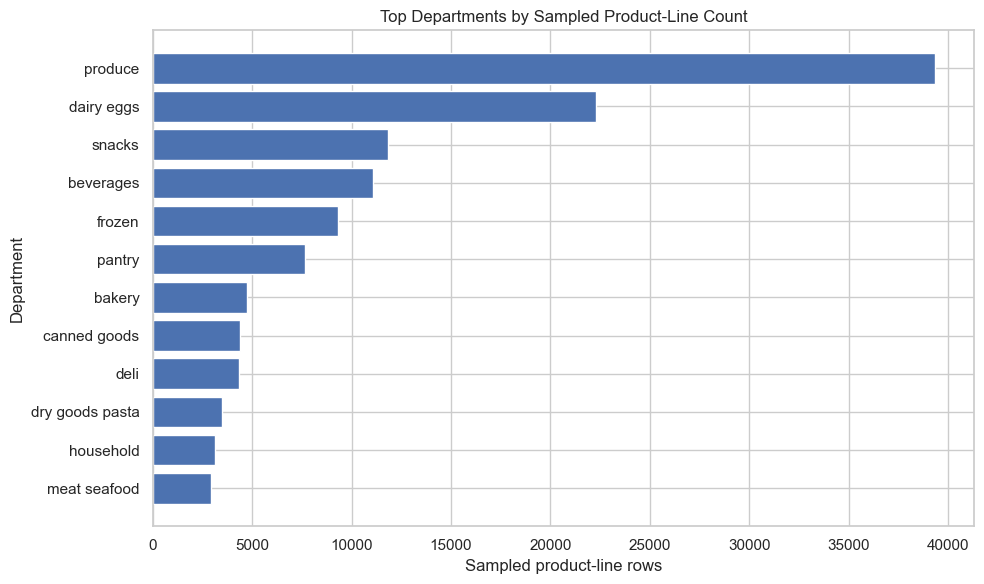

Observation 1: identify the department with the largest displayed sampled count.
Observation 2: compare counts across departments; these are sample counts, not full-data totals.


In [14]:
top=department_summary.dropna(subset=["sampled_lines"]).head(12).sort_values("sampled_lines")
plt.figure(figsize=(10,6))
plt.barh(top.index.astype(str),top["sampled_lines"])
plt.title("Top Departments by Sampled Product-Line Count")
plt.xlabel("Sampled product-line rows")
plt.ylabel("Department")
plt.tight_layout()
plt.show()
print("Observation 1: identify the department with the largest displayed sampled count.")
print("Observation 2: compare counts across departments; these are sample counts, not full-data totals.")

# UNIT V — DESCRIPTIVE STATISTICS

# Task 7 — Central Tendency
Calculate mean, median and mode for at least two numerical variables. Mean is sensitive to extreme values; median is the middle ordered value; mode is most frequent. Missing order-gap values are excluded, not converted to zero.

In [15]:
numeric = orders_work[["cart_size","days_since_prior_order"]]
central = pd.DataFrame({"mean":numeric.mean(),"median":numeric.median(),
                        "mode":numeric.mode(dropna=True).iloc[0]})
central["mean_minus_median"]=central["mean"]-central["median"]
display(central)
print("Compare mean and median; a large difference can suggest skewness or extreme values.")

,mean,median,mode,mean_minus_median
cart_size,10.107073,8.0,5.0,2.107073
days_since_prior_order,11.114836,7.0,30.0,4.114836


Compare mean and median; a large difference can suggest skewness or extreme values.


# Task 8 — Dispersion
Variance and standard deviation describe spread; range is max minus min. Variance has squared units. Use sample variance and standard deviation (`ddof=1`).

In [16]:
dispersion=pd.DataFrame({
    "sample_variance_ddof1":numeric.var(ddof=1),
    "sample_std_ddof1":numeric.std(ddof=1),
    "minimum":numeric.min(),"maximum":numeric.max(),
    "range":numeric.max()-numeric.min()})
display(dispersion)

,sample_variance_ddof1,sample_std_ddof1,minimum,maximum,range
cart_size,56.886687,7.542326,1.0,145.0,144.0
days_since_prior_order,84.764000,9.206737,0.0,30.0,30.0


# Task 9 — Percentiles, Quantiles and Five-Number Summary
Quartiles divide ordered observations into four parts. IQR = Q3 − Q1 and describes the middle 50%.

In [17]:
percentiles=numeric.quantile([.10,.25,.50,.75,.90]).T
percentiles.columns=["P10","Q1_P25","Median_P50","Q3_P75","P90"]
display(percentiles)
five=pd.DataFrame({"minimum":numeric.min(),"Q1":numeric.quantile(.25),
    "median":numeric.median(),"Q3":numeric.quantile(.75),"maximum":numeric.max()})
five["IQR"]=five["Q3"]-five["Q1"]
display(five)

,P10,Q1_P25,Median_P50,Q3_P75,P90
cart_size,2.0,5.0,8.0,14.0,20.0
days_since_prior_order,2.0,4.0,7.0,15.0,30.0


,minimum,Q1,median,Q3,maximum,IQR
cart_size,1.0,5.0,8.0,14.0,145.0,9.0
days_since_prior_order,0.0,4.0,7.0,15.0,30.0,11.0


# Task 10 — Skewness and Kurtosis
Positive skew has a longer right tail; negative skew has a longer left tail; near-zero skew suggests approximate symmetry. Pandas `.kurt()` reports Fisher/excess kurtosis, whose normal reference is approximately zero. Interpret with histograms and box plots.

In [18]:
shape=pd.DataFrame({"skewness":numeric.skew(),
                     "Fisher_excess_kurtosis":numeric.kurt()})
display(shape)

,skewness,Fisher_excess_kurtosis
cart_size,1.556140,4.039306
days_since_prior_order,0.987922,-0.288909


# Task 11 — Common Distributions
Inspect actual Instacart variables first. Do not force a distribution label. If a required shape is not clearly present, use the labelled simulated demonstration. Simulated values are not dataset observations.

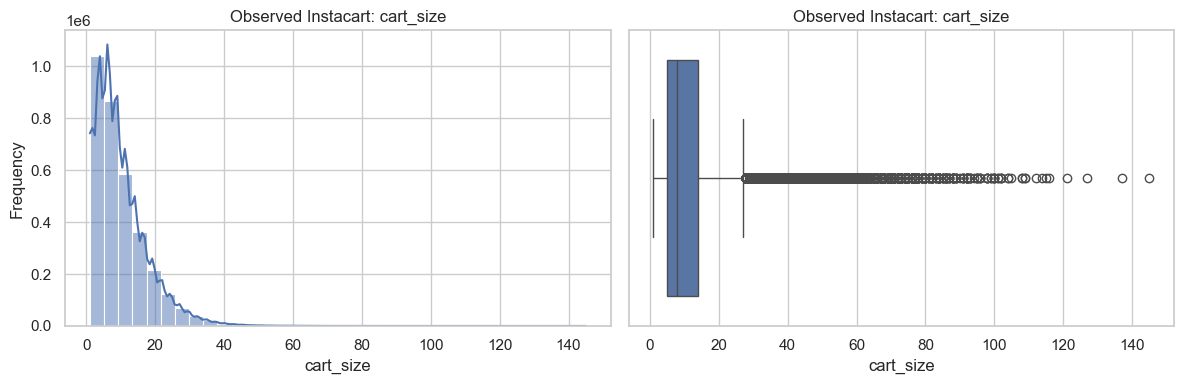

cart_size skew: 1.556 excess kurtosis: 4.039
Observation 1: inspect symmetry, tail direction and peaks in the histogram.
Observation 2: inspect median, spread and potential extreme values in the box plot.


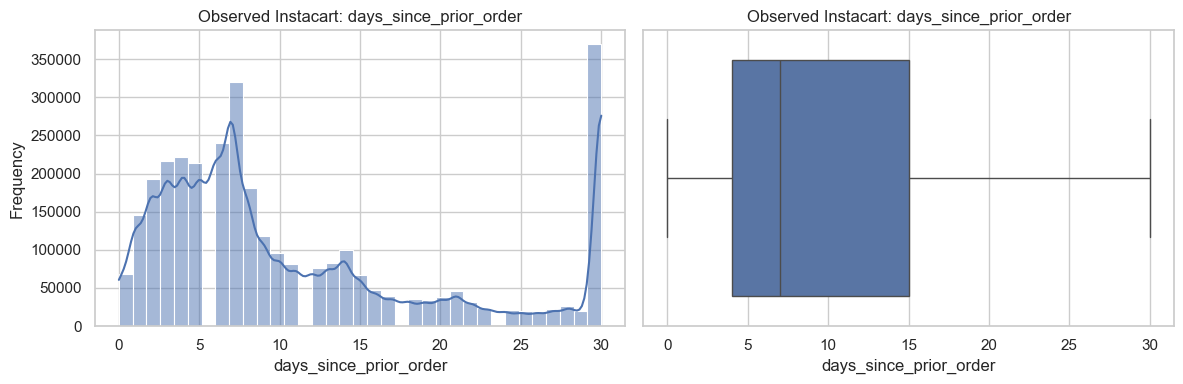

days_since_prior_order skew: 0.988 excess kurtosis: -0.289
Observation 1: inspect symmetry, tail direction and peaks in the histogram.
Observation 2: inspect median, spread and potential extreme values in the box plot.


In [19]:
for col in ["cart_size","days_since_prior_order"]:
    values=orders_work[col].dropna()
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    sns.histplot(values,bins=35,kde=True,ax=ax[0])
    ax[0].set_title(f"Observed Instacart: {col}")
    ax[0].set_xlabel(col); ax[0].set_ylabel("Frequency")
    sns.boxplot(x=values,ax=ax[1])
    ax[1].set_title(f"Observed Instacart: {col}")
    ax[1].set_xlabel(col)
    plt.tight_layout(); plt.show()
    print(col,"skew:",round(values.skew(),3),"excess kurtosis:",round(values.kurt(),3))
    print("Observation 1: inspect symmetry, tail direction and peaks in the histogram.")
    print("Observation 2: inspect median, spread and potential extreme values in the box plot.")

## Task 11 — Controlled simulated distribution shapes
These examples demonstrate approximately normal, positive skew, negative skew and bimodal shapes only when the real data do not clearly show all four. They are simulated controls, not Instacart observations.

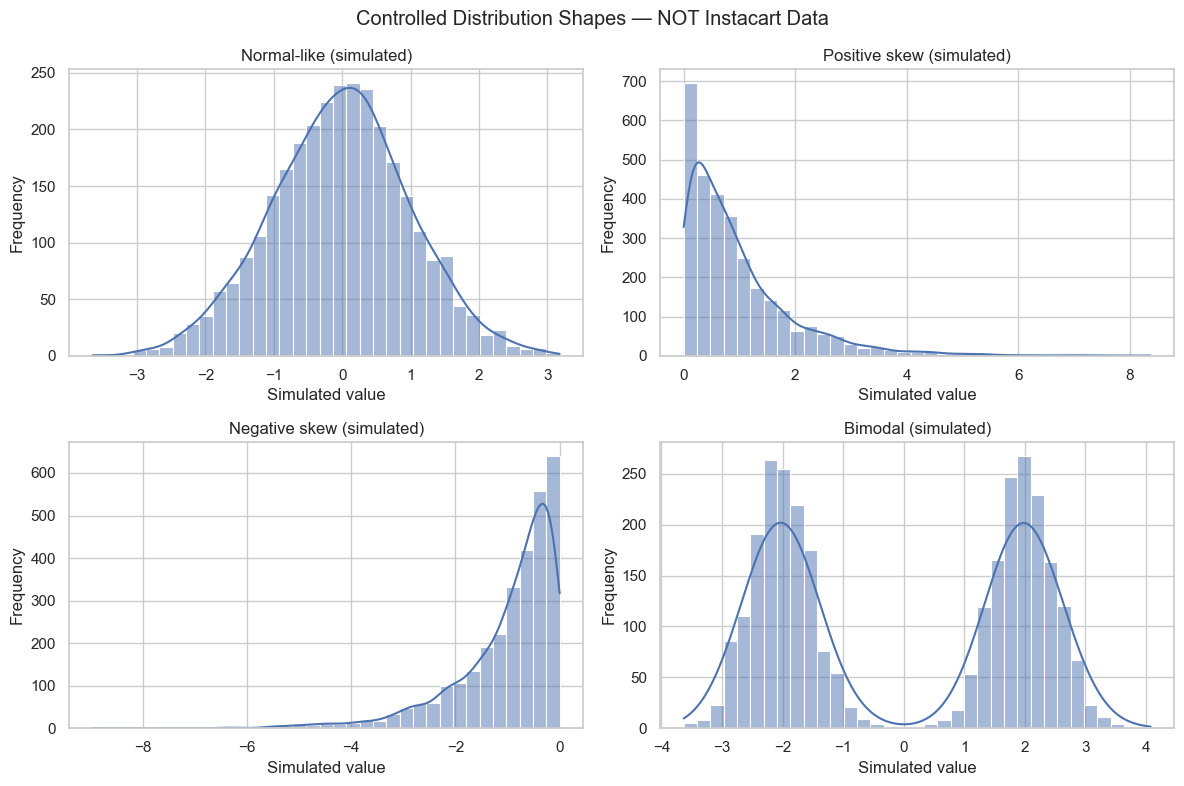

Observation 1: normal-like data are approximately symmetric.
Observation 2: skewed examples have directional tails; bimodal example has two peaks.


In [20]:
r=np.random.default_rng(SEED)
sim={"Normal-like (simulated)":r.normal(0,1,3000),
     "Positive skew (simulated)":r.exponential(1,3000),
     "Negative skew (simulated)":-r.exponential(1,3000),
     "Bimodal (simulated)":np.r_[r.normal(-2,.5,1500),r.normal(2,.5,1500)]}
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,(label,vals) in zip(axes.flat,sim.items()):
    sns.histplot(vals,bins=35,kde=True,ax=ax)
    ax.set_title(label); ax.set_xlabel("Simulated value"); ax.set_ylabel("Frequency")
plt.suptitle("Controlled Distribution Shapes — NOT Instacart Data")
plt.tight_layout(); plt.show()
print("Observation 1: normal-like data are approximately symmetric.")
print("Observation 2: skewed examples have directional tails; bimodal example has two peaks.")

# Task 12 — Empirical Rule (68–95–99.7)
For an approximately normal distribution, about 68%, 95%, and 99.7% of values lie within mean ±1, ±2, and ±3 SD. Compare observed percentages for basket size. If strongly skewed, explain why the rule may not fit.

In [21]:
x=orders_work["cart_size"].dropna()
mu=x.mean(); sd=x.std(ddof=0)
rows=[]
for k,ref in [(1,68.0),(2,95.0),(3,99.7)]:
    observed=x.between(mu-k*sd,mu+k*sd).mean()*100
    rows.append({"interval":f"mean ± {k} SD","observed_percent":observed,
                 "normal_reference_percent":ref,"difference_pp":observed-ref})
display(pd.DataFrame(rows).round(2))

,interval,observed_percent,normal_reference_percent,difference_pp
0,mean ± 1 SD,74.64,68.0,6.64
1,mean ± 2 SD,95.52,95.0,0.52
2,mean ± 3 SD,98.49,99.7,-1.21


# Task 13 — Sampling and Central Limit Theorem
Draw 500 fixed-seed simple random samples without replacement from order-level basket sizes. The CLT says the distribution of sample means tends toward normality under suitable conditions. Sample means vary, and their spread generally decreases as sample size increases. Repeated orders from one user may not be independent.

Population n: 3346083 sample size: 30 repetitions: 500
Population mean: 10.10707325550502 mean of sample means: 10.0748 SD of sample means: 1.3512129784108988


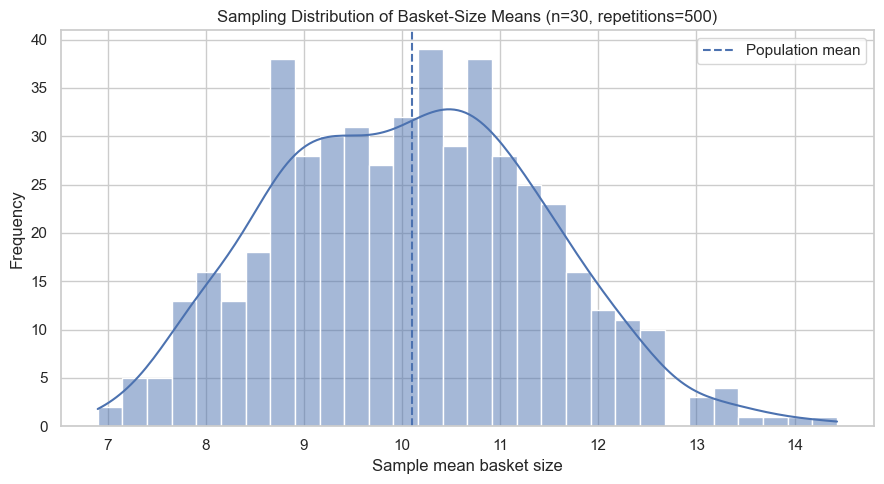

Observation 1: compare the centre of sample means with the population mean.
Observation 2: sample-mean spread is sampling variability, not individual-order spread.


In [22]:
population=orders_work["cart_size"].dropna().to_numpy()
if len(population)<100: raise ValueError("Too few basket observations for CLT demonstration.")
crng=np.random.default_rng(SEED)
n=min(30,len(population)); reps=500
means=np.array([crng.choice(population,size=n,replace=False).mean() for _ in range(reps)])
print("Population n:",len(population),"sample size:",n,"repetitions:",reps)
print("Population mean:",population.mean(),"mean of sample means:",means.mean(),
      "SD of sample means:",means.std(ddof=1))
plt.figure(figsize=(9,5)); sns.histplot(means,bins=30,kde=True)
plt.axvline(population.mean(),linestyle="--",label="Population mean")
plt.title(f"Sampling Distribution of Basket-Size Means (n={n}, repetitions={reps})")
plt.xlabel("Sample mean basket size"); plt.ylabel("Frequency"); plt.legend()
plt.tight_layout(); plt.show()
print("Observation 1: compare the centre of sample means with the population mean.")
print("Observation 2: sample-mean spread is sampling variability, not individual-order spread.")

In [23]:
comparison=[]
for n in [10,30,50,100]:
    if n<=len(population):
        ms=[crng.choice(population,size=n,replace=False).mean() for _ in range(reps)]
        comparison.append({"sample_size":n,"mean_of_means":np.mean(ms),
                           "sd_of_means":np.std(ms,ddof=1)})
display(pd.DataFrame(comparison).round(3))

,sample_size,mean_of_means,sd_of_means
0,10,10.272,2.379
1,30,10.105,1.377
2,50,10.053,1.062
3,100,10.126,0.720


# Task 14 — Covariance and Correlation
Covariance is scale-dependent. Pearson correlation measures linear association; Spearman measures monotonic rank association. Correlations range from −1 to +1. Correlation is not causation: confounding, reverse relationships or coincidence may explain an association.

In [24]:
cols=["cart_size","unique_products","reordered_items","reorder_rate",
      "order_number","days_since_prior_order","order_hour_of_day"]
corr_data=orders_work[cols].dropna()
pearson=corr_data.corr(method="pearson")
spearman=corr_data.corr(method="spearman")
cov=corr_data[["cart_size","unique_products","reordered_items","order_number"]].cov()
display(pearson); display(spearman); display(cov)

,cart_size,unique_products,reordered_items,reorder_rate,order_number,days_since_prior_order,order_hour_of_day
cart_size,1.000000,1.000000,0.820702,-0.040884,-0.002496,0.057544,-0.005927
unique_products,1.000000,1.000000,0.820702,-0.040884,-0.002496,0.057544,-0.005927
reordered_items,0.820702,0.820702,1.000000,0.404502,0.204312,-0.063828,-0.022602
reorder_rate,-0.040884,-0.040884,0.404502,1.000000,0.370804,-0.189626,-0.031759
order_number,-0.002496,-0.002496,0.204312,0.370804,1.000000,-0.360495,-0.035454
days_since_prior_order,0.057544,0.057544,-0.063828,-0.189626,-0.360495,1.000000,0.000863
order_hour_of_day,-0.005927,-0.005927,-0.022602,-0.031759,-0.035454,0.000863,1.000000


,cart_size,unique_products,reordered_items,reorder_rate,order_number,days_since_prior_order,order_hour_of_day
cart_size,1.000000,1.000000,0.778275,-0.131057,0.010491,0.098457,-0.000961
unique_products,1.000000,1.000000,0.778275,-0.131057,0.010491,0.098457,-0.000961
reordered_items,0.778275,0.778275,1.000000,0.423977,0.311773,-0.018729,-0.021846
reorder_rate,-0.131057,-0.131057,0.423977,1.000000,0.463949,-0.157179,-0.037728
order_number,0.010491,0.010491,0.311773,0.463949,1.000000,-0.389231,-0.041828
days_since_prior_order,0.098457,0.098457,-0.018729,-0.157179,-0.389231,1.000000,-0.009073
order_hour_of_day,-0.000961,-0.000961,-0.021846,-0.037728,-0.041828,-0.009073,1.000000


,cart_size,unique_products,reordered_items,order_number
cart_size,56.959471,56.959471,36.085044,-0.335774
unique_products,56.959471,56.959471,36.085044,-0.335774
reordered_items,36.085044,36.085044,33.940455,21.216187
order_number,-0.335774,-0.335774,21.216187,317.708436


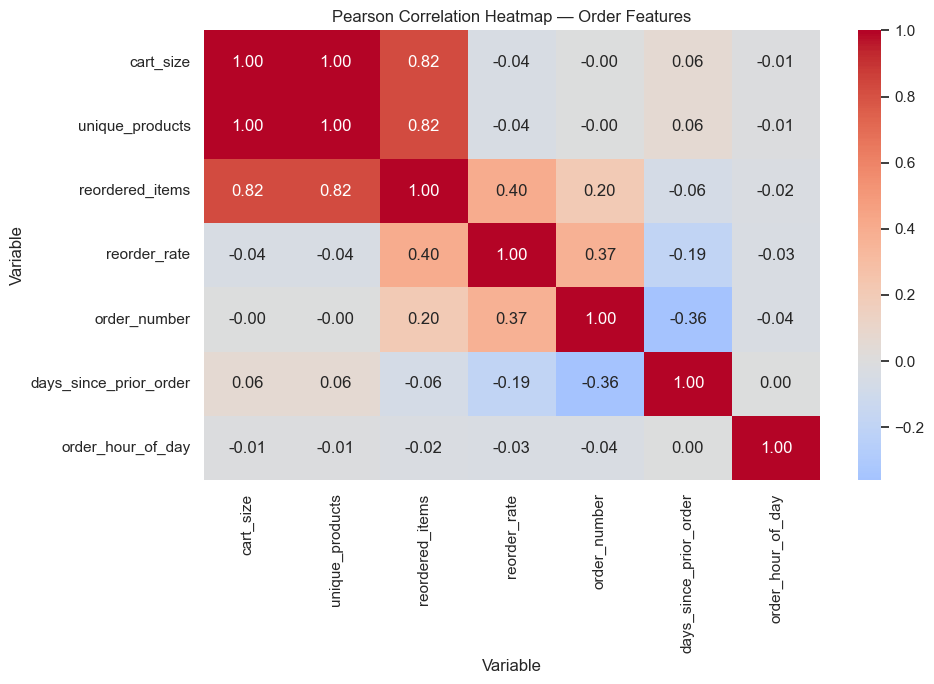

Observation 1: identify strongest positive/negative displayed correlations.
Observation 2: compare Pearson and Spearman; differences can indicate non-linearity, outliers or rank effects.


In [25]:
plt.figure(figsize=(10,7)); sns.heatmap(pearson,annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Pearson Correlation Heatmap — Order Features")
plt.xlabel("Variable"); plt.ylabel("Variable"); plt.tight_layout(); plt.show()
print("Observation 1: identify strongest positive/negative displayed correlations.")
print("Observation 2: compare Pearson and Spearman; differences can indicate non-linearity, outliers or rank effects.")

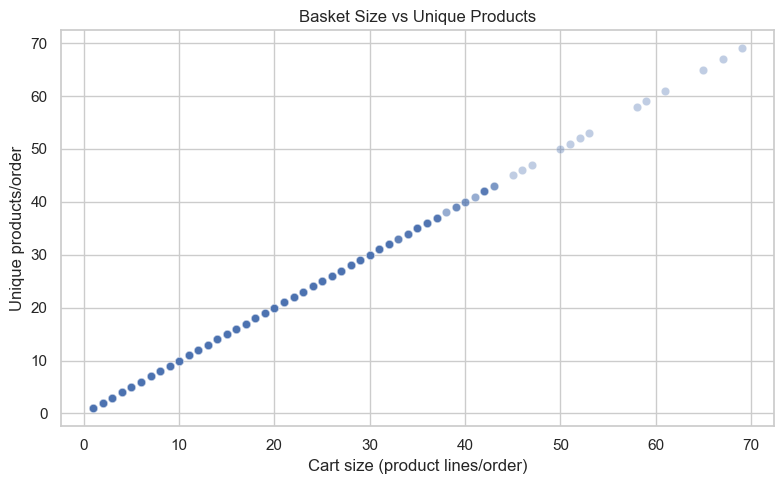

Pearson: 1.0
Spearman: 1.0
Observation 1: describe the direction and strength using the displayed coefficients.
Observation 2: describe the scatter pattern. Do not claim causation.


In [26]:
scatter=corr_data.sample(n=min(5000,len(corr_data)),random_state=SEED)
plt.figure(figsize=(8,5))
sns.scatterplot(data=scatter,x="cart_size",y="unique_products",alpha=.35)
plt.title("Basket Size vs Unique Products")
plt.xlabel("Cart size (product lines/order)"); plt.ylabel("Unique products/order")
plt.tight_layout(); plt.show()
print("Pearson:",corr_data.cart_size.corr(corr_data.unique_products,method="pearson"))
print("Spearman:",corr_data.cart_size.corr(corr_data.unique_products,method="spearman"))
print("Observation 1: describe the direction and strength using the displayed coefficients.")
print("Observation 2: describe the scatter pattern. Do not claim causation.")

# Task 15 — Outlier Detection
IQR fences are Q1 − 1.5×IQR and Q3 + 1.5×IQR. Z-score is distance from mean in standard deviations; use |Z| > 3 as an exploratory threshold. Report count and percentage for both. Inspect source values before deciding how to handle them.

,method,threshold,count,percent
0,IQR,< -8.50 or > 27.50,110280,3.296
1,Z-score,|Z| > 3,50573,1.511


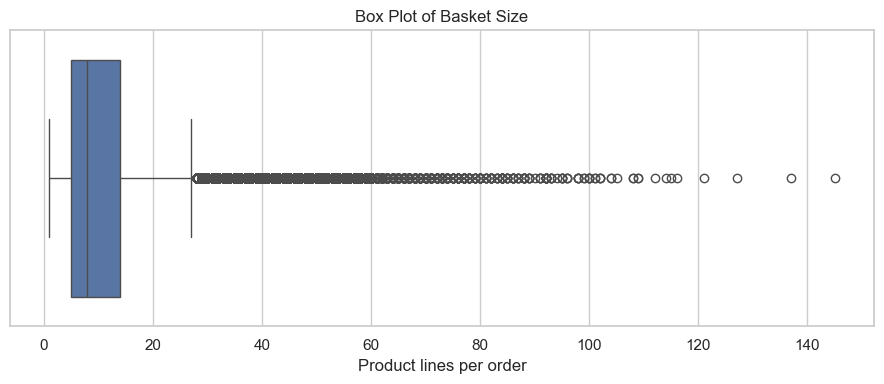

Observation 1: the box plot shows median, quartiles and potential extreme points.
Observation 2: IQR and Z-score can flag different rows because they use different reference measures.


,order_id,user_id,cart_size,iqr_flag,z_score,z_flag
380638,1564244,22906,145.0,True,17.884793,True
2159899,790903,129928,137.0,True,16.824112,True
380637,61355,22906,127.0,True,15.498261,True
1327221,2970392,79738,121.0,True,14.702751,True
2159902,2069920,129928,116.0,True,14.039825,True
2159904,3308010,129928,115.0,True,13.907240,True
816162,2753324,49110,114.0,True,13.774655,True
2159887,2499774,129928,112.0,True,13.509485,True
1009973,2621625,60694,109.0,True,13.111729,True
416261,77151,25070,109.0,True,13.111729,True


In [27]:
out=orders_work[["order_id","user_id","cart_size"]].dropna().copy()
q1=out.cart_size.quantile(.25); q3=out.cart_size.quantile(.75); iqr=q3-q1
lo=q1-1.5*iqr; hi=q3+1.5*iqr
out["iqr_flag"]=(out.cart_size<lo)|(out.cart_size>hi)
z=(out.cart_size-out.cart_size.mean())/out.cart_size.std(ddof=0)
out["z_score"]=z; out["z_flag"]=z.abs()>3
display(pd.DataFrame([
 {"method":"IQR","threshold":f"< {lo:.2f} or > {hi:.2f}",
  "count":int(out.iqr_flag.sum()),"percent":out.iqr_flag.mean()*100},
 {"method":"Z-score","threshold":"|Z| > 3",
  "count":int(out.z_flag.sum()),"percent":out.z_flag.mean()*100}
]).round(3))
plt.figure(figsize=(9,4)); sns.boxplot(x=out.cart_size)
plt.title("Box Plot of Basket Size"); plt.xlabel("Product lines per order")
plt.tight_layout(); plt.show()
print("Observation 1: the box plot shows median, quartiles and potential extreme points.")
print("Observation 2: IQR and Z-score can flag different rows because they use different reference measures.")
display(out.loc[out.iqr_flag|out.z_flag].sort_values("cart_size",ascending=False).head(15))

# Task 16 — Outlier Handling
Compare removal, capping and retention on separate derived Series. Do not overwrite original values. A large basket may be genuine, so retention is the default unless inspection confirms an error. Compare mean, median, standard deviation and range.

In [28]:
original=out.cart_size.copy()
removed=original.loc[~out.iqr_flag].copy()
capped=original.clip(lower=lo,upper=hi)
def summary(s,label):
    return {"strategy":label,"rows":s.count(),"mean":s.mean(),"median":s.median(),
            "std":s.std(),"range":s.max()-s.min()}
display(pd.DataFrame([summary(original,"Retention/original"),
                      summary(removed,"Remove IQR flags"),
                      summary(capped,"Cap at IQR fences")]).round(3))
print("Decision: retain plausible baskets; only correct or remove values verified to be erroneous.")

,strategy,rows,mean,median,std,range
0,Retention/original,3346083,10.107,8.0,7.542,144.0
1,Remove IQR flags,3235803,9.294,8.0,6.100,26.0
2,Cap at IQR fences,3346083,9.894,8.0,6.822,26.5


Decision: retain plausible baskets; only correct or remove values verified to be erroneous.


# Task 17 — Data Quality Assessment (Common Unit IV/V)
Check completeness, consistency, accuracy/plausibility, duplicates, validity/data types, key integrity and integration quality. Product-line checks refer to the reproducible sample; the other tables are loaded as complete tables.

In [29]:
quality_tables={"orders":raw_orders,"products":raw_products,"aisles":raw_aisles,
                "departments":raw_departments,"product_line_sample":order_product_sample}
missing_rows=[]
for name,df in quality_tables.items():
    for col in df.columns:
        missing_rows.append({"table":name,"column":col,"missing":int(df[col].isna().sum()),
            "missing_pct":round(df[col].isna().mean()*100,2),"dtype":str(df[col].dtype)})
display(pd.DataFrame(missing_rows))

,table,column,missing,missing_pct,dtype
0,orders,order_id,0,0.00,int32
1,orders,user_id,0,0.00,int32
2,orders,eval_set,0,0.00,category
3,orders,order_number,0,0.00,int16
4,orders,order_dow,0,0.00,int8
5,orders,order_hour_of_day,0,0.00,int8
6,orders,days_since_prior_order,206209,6.03,float32
7,products,product_id,0,0.00,int32
8,products,product_name,0,0.00,str
9,products,aisle_id,0,0.00,int16


In [30]:
# Consistency: observed categories and label whitespace.
consistency={
 "eval_set_values":sorted(raw_orders.eval_set.dropna().astype(str).unique().tolist()),
 "order_dow_values":sorted(raw_orders.order_dow.dropna().unique().tolist()),
 "hour_min_max":(int(raw_orders.order_hour_of_day.min()),int(raw_orders.order_hour_of_day.max())),
 "aisle_labels_with_outer_spaces":int(raw_aisles.aisle.astype(str).ne(raw_aisles.aisle.astype(str).str.strip()).sum()),
 "department_labels_with_outer_spaces":int(raw_departments.department.astype(str).ne(raw_departments.department.astype(str).str.strip()).sum())
}
display(pd.Series(consistency,dtype="object").to_frame("observed_check"))
display(raw_departments.department.value_counts(dropna=False))

,observed_check
eval_set_values,"[prior, test, train]"
order_dow_values,"[0, 1, 2, 3, 4, 5, 6]"
hour_min_max,"(0, 23)"
aisle_labels_with_outer_spaces,0
department_labels_with_outer_spaces,0


department
frozen             1
other              1
bakery             1
produce            1
alcohol            1
international      1
beverages          1
pets               1
dry goods pasta    1
bulk               1
personal care      1
meat seafood       1
pantry             1
breakfast          1
canned goods       1
dairy eggs         1
household          1
babies             1
snacks             1
deli               1
missing            1
Name: count, dtype: int64

In [31]:
# Accuracy/plausibility checks based on dataset domains.
display(pd.DataFrame([
 ["order_dow outside 0..6",int((~raw_orders.order_dow.between(0,6)).sum())],
 ["hour outside 0..23",int((~raw_orders.order_hour_of_day.between(0,23)).sum())],
 ["order_number <= 0",int((raw_orders.order_number<=0).sum())],
 ["negative days_since_prior_order",int((raw_orders.days_since_prior_order<0).sum())],
 ["sample add_to_cart_order <= 0",int((order_product_sample.add_to_cart_order<=0).sum())],
 ["sample reordered not 0/1",int((~order_product_sample.reordered.isin([0,1])).sum())]
],columns=["domain_check","invalid_count"]))

,domain_check,invalid_count
0,order_dow outside 0..6,0
1,hour outside 0..23,0
2,order_number <= 0,0
3,negative days_since_prior_order,0
4,sample add_to_cart_order <= 0,0
5,sample reordered not 0/1,0


In [32]:
# Exact duplicate rows and candidate primary-key duplicates.
display(pd.DataFrame([{"table":n,"exact_duplicate_rows":int(d.duplicated().sum())}
                      for n,d in quality_tables.items()]))
display(pd.DataFrame([
 ["orders","order_id",int(raw_orders.order_id.duplicated().sum())],
 ["products","product_id",int(raw_products.product_id.duplicated().sum())],
 ["aisles","aisle_id",int(raw_aisles.aisle_id.duplicated().sum())],
 ["departments","department_id",int(raw_departments.department_id.duplicated().sum())]
],columns=["table","candidate_key","duplicate_key_rows"]))

,table,exact_duplicate_rows
0,orders,0
1,products,0
2,aisles,0
3,departments,0
4,product_line_sample,0


,table,candidate_key,duplicate_key_rows
0,orders,order_id,0
1,products,product_id,0
2,aisles,aisle_id,0
3,departments,department_id,0


In [33]:
# Foreign-key integrity and integration quality.
display(pd.DataFrame([
 ["sample order_id -> orders",int((~order_product_sample.order_id.isin(raw_orders.order_id)).sum())],
 ["sample product_id -> products",int((~order_product_sample.product_id.isin(raw_products.product_id)).sum())],
 ["products aisle_id -> aisles",int((~raw_products.aisle_id.isin(raw_aisles.aisle_id)).sum())],
 ["products department_id -> departments",int((~raw_products.department_id.isin(raw_departments.department_id)).sum())]
],columns=["relationship","unmatched_rows"]))
print("Fact rows before:",len(fact_source),"after:",len(fact),"difference:",len(fact)-len(fact_source))

,relationship,unmatched_rows
0,sample order_id -> orders,0
1,sample product_id -> products,0
2,products aisle_id -> aisles,0
3,products department_id -> departments,0


Fact rows before: 133846 after: 133846 difference: 0


## Task 17 — Quality decisions
Use the actual reports to document missingness, inconsistent labels, implausible values, duplicate rows/keys and unmatched foreign keys. Missing `days_since_prior_order` can be expected for first orders. Repeated `order_id` in product-line data is expected. Do not delete records unless the evidence and table grain justify it. Explain how each issue could affect aggregation or conclusions.

# 18. Mandatory visualisation checklist
PDF-required plots: histogram, box plot, scatter plot, bar/comparison chart, correlation heatmap and sampling distribution. The notebook generates these with titles and labelled axes. For each graph, add at least two **specific observations from your actual displayed output** before submission.

In [34]:
display(pd.DataFrame([
 ["Histogram","Tasks 11/12","Observed numerical variables"],
 ["Box plot","Tasks 11/15","Basket size"],
 ["Scatter plot","Task 14","Basket size vs unique products"],
 ["Bar chart","Task 2","Sampled department counts"],
 ["Correlation heatmap","Task 14","Pearson matrix"],
 ["Sampling distribution","Task 13","Repeated sample means"]
],columns=["required_plot","task","notebook_section"]))

,required_plot,task,notebook_section
0,Histogram,Tasks 11/12,Observed numerical variables
1,Box plot,Tasks 11/15,Basket size
2,Scatter plot,Task 14,Basket size vs unique products
3,Bar chart,Task 2,Sampled department counts
4,Correlation heatmap,Task 14,Pearson matrix
5,Sampling distribution,Task 13,Repeated sample means


# 19. Findings and project summary
The next cell prints actual results. Use these outputs to write evidence-based findings; do not invent numerical claims.

In [35]:
print("INSTACART PROJECT SUMMARY")
print("Orders:",f"{len(raw_orders):,}","Products:",f"{len(raw_products):,}")
print("Aisles:",f"{len(raw_aisles):,}","Departments:",f"{len(raw_departments):,}")
print("Prior rows scanned:",f"{prior_scanned:,}","Train rows scanned:",f"{train_scanned:,}")
print("Product-line sample rows:",f"{len(order_product_sample):,}")
print("Orders with basket features:",f"{orders_work.cart_size.notna().sum():,}")
print("Mean basket size:",round(orders_work.cart_size.mean(),3))
print("Median basket size:",round(orders_work.cart_size.median(),3))
print("Mean reorder rate:",round(orders_work.reorder_rate.mean(),3))
print("Most frequent order hour:",int(raw_orders.order_hour_of_day.mode().iloc[0]))
print("Most frequent day code:",int(raw_orders.order_dow.mode().iloc[0]))
display(department_summary.head(5))

INSTACART PROJECT SUMMARY
Orders: 3,421,083 Products: 49,688
Aisles: 134 Departments: 21
Prior rows scanned: 32,434,489 Train rows scanned: 1,384,617
Product-line sample rows: 133,846
Orders with basket features: 3,346,083
Mean basket size: 10.107
Median basket size: 8.0
Mean reorder rate: 0.599
Most frequent order hour: 10
Most frequent day code: 0


,sampled_lines,unique_products,unique_orders,mean_reordered,median_cart_position,min_cart_position,max_cart_position
department,,,,,,,
produce,39338,1050,38872,0.651863,6.0,1,85
dairy eggs,22292,1908,22149,0.674412,6.0,1,70
snacks,11848,2526,11780,0.577059,7.0,1,90
beverages,11092,1778,11052,0.649748,5.0,1,83
frozen,9300,1820,9252,0.543656,7.0,1,65


# 20. Limitations and future scope
1. Detailed product-line fact analysis uses a reproducible sample; department sample counts are not full-dataset totals.
2. Order-level basket metrics are accumulated from all rows scanned in prior/train files.
3. The dataset has day/hour and relative order-gap fields, not full calendar timestamps.
4. Observational associations do not prove causation.
5. Multiple orders from the same user may be dependent, affecting simple random-sampling assumptions.
6. Future work: product association rules, customer segmentation, sequential purchase analysis and recommendation systems.

# 21. Final conclusion
Complete this after running the notebook. Summarise actual order timing, basket-size patterns, department differences (labelled sample), reorder behaviour, distribution shape, correlation findings, outlier decisions and data-quality results. State limitations and answer the central analytical question. Do not insert numbers until generated by the notebook.

# Viva Preparation Notes

**Project overview**
1. Objective? Analyse grocery order timing, basket size, departments and reorder behaviour.
2. Why Instacart? It contains related order, product, aisle and department tables.
3. Why chunking? It reads large CSVs in smaller blocks to reduce peak memory.
4. Why sample product lines? To enable detailed joins and plots without loading all product lines into RAM.
5. Are all outputs exact? Order-level basket features are accumulated from all scanned split rows; detailed product-line fact analysis uses a labelled sample.

**Unit IV**
6. Feature engineering? Creating useful variables from existing columns.
7. Four features? Cart size, unique products, reorder rate and weekend flag.
8. Why preserve missing order gap? First order has no previous order.
9. `groupby()`? Forms groups.
10. `agg()` vs `transform()`? Aggregation reduces groups; transform returns aligned group values.
11. Pivot table? Aggregated numerical summary across two dimensions.
12. Crosstab? Frequency/proportion table of categories.
13. Wide vs long? Measures in columns vs variable/value rows.
14. `melt()` and `pivot()`? Wide-to-long and long-to-wide.
15. `stack()` and `unstack()`? Move column levels to index and index levels to columns.
16. Primary/foreign key? Unique row identifier / reference to another table's key.
17. One-to-many? One order can have many product lines.
18. `validate='many_to_one'`? Ensures right-side keys are unique for the merge.
19. Join types? Inner matched only; left all left; right all right; outer all both.
20. `join()`? Index-aligned combination.
21. `concat()`? Appends DataFrames.
22. Why suffixes? Resolve overlapping non-key column names.
23. Why row multiplication? One parent can match multiple child rows; multiple child tables can inflate counts.

**Unit V**
24. Mean/median/mode? Average/middle/most frequent.
25. Variance and standard deviation? Spread; variance is squared units.
26. Range? Maximum minus minimum.
27. Quartiles and IQR? Quartiles divide data into four; IQR is Q3−Q1.
28. Positive/negative skew? Longer right/left tail.
29. Excess kurtosis? Fisher kurtosis relative to normal reference zero.
30. Empirical rule? 68%, 95%, 99.7% within 1, 2, 3 SD for normal data.
31. CLT? Sample means tend toward normality under suitable conditions as sample size increases.
32. Covariance? Co-movement, scale-dependent.
33. Pearson vs Spearman? Linear vs monotonic rank association.
34. Correlation proves causation? No.
35. Outlier? Unusually distant observation.
36. IQR rule? Outside Q1−1.5×IQR and Q3+1.5×IQR.
37. Z-score? Number of SDs from mean; here |Z|>3 is exploratory.
38. Removal/capping/retention? Exclude, limit, or keep valid observations.

**Practical**
39. Why raw data unchanged? Reproducibility.
40. What if kernel restarts? Variables clear; run all cells again.
41. Why not remove all outliers? Some are valid rare cases.
42. What is a merge indicator? Shows matched and unmatched rows.
43. What is the main limitation? Product-line integration is sample-based and there is no full timestamp.

# Final submission checklist (from the assignment)
- [ ] Kaggle source URL and current licence/usage conditions checked.
- [ ] All six CSVs are in `data`.
- [ ] Raw tables preserved; working copies used.
- [ ] Task 1: four or more documented features, formulas, types and missing-value decisions.
- [ ] Task 2: groupby, multiple agg functions, transform, group comparison and bar chart.
- [ ] Task 3: pivot table and crosstab.
- [ ] Task 4: melt, pivot, stack and unstack.
- [ ] Task 5: merge, join, concat, join types, keys, relationships, suffixes and index alignment.
- [ ] Task 6: integration plan, duplicate keys, unmatched records and row-count validation.
- [ ] Tasks 7–10: central tendency, dispersion, percentiles, quantiles, five-number summary, skewness and kurtosis.
- [ ] Task 11: actual and clearly labelled simulated distributions where needed.
- [ ] Task 12: empirical rule.
- [ ] Task 13: repeated sampling, sampling distribution and sample-size comparison.
- [ ] Task 14: covariance, Pearson, Spearman, heatmap, scatter plot and non-causal interpretation.
- [ ] Tasks 15–16: IQR/Z-score, source inspection, removal/capping/retention comparison.
- [ ] Task 17: completeness, consistency, plausibility, duplicates, validity, key integrity and integration quality.
- [ ] All six mandatory plots have titles, labelled axes and two specific observations based on actual outputs.
- [ ] Every task includes objective, concept, methodology, code, output, interpretation, observations, decision and conclusion.
- [ ] Findings and conclusion completed from actual outputs.
- [ ] Run all cells from first to last without unresolved errors; save outputs.
- [ ] Prepare to explain code and decisions in the viva.

**End of Minor Project 02 — CA 03.**